# 01 · Exploratory data analysis

**Goal:** understand the raw HDB resale data before cleaning or modeling it: what each column holds, what is missing or malformed, how prices are distributed and how they move over time.

**Output:** a list of findings, each turned into a cleaning or modeling decision (recorded at the end of this notebook). Reusable code goes into the `hdb_resale` package, never only here.

**Data:** the DVC-versioned raw snapshot `data/raw/resale.csv` (see `data/raw/snapshot.json`). To get it: `uv run dvc pull`.

**Rule for this notebook:** we explore the whole dataset's *structure*, but take no modeling decision from the most recent 12 months: they are the test period of the rolling backtest (project ADR-0001).

## Contents

1. Load and structure: columns, types, missing values

2. Prices: distribution and trend over time
3. What drives price besides time


## 1. Load and structure

Load the snapshot exactly as published: no type conversion yet, so we see what pandas infers on its own.

In [11]:
from pathlib import Path

import pandas as pd

# The notebook runs from notebooks/, the data lives at the project root
PROJECT_ROOT = Path.cwd().parent
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "resale.csv"

raw = pd.read_csv(RAW_PATH)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

242,537 rows x 11 columns


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.0,Improved,1979,61 years 04 months,232000.0
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.0,New Generation,1978,60 years 07 months,250000.0
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,262000.0
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.0,New Generation,1980,62 years 01 month,265000.0
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,265000.0


### Column types and missing values

For each column: the type pandas inferred, how many values are missing, how many distinct values it has, and one example.

In [12]:
# One row per column: inferred type, missing values, distinct values, an example
structure = pd.DataFrame(
    {
        "dtype": raw.dtypes.astype(str),
        "missing": raw.isna().sum(),
        "distinct": raw.nunique(),
        "example": raw.iloc[0],
    }
)
structure

,dtype,missing,distinct,example
month,str,0,118,2017-01
town,str,0,26,ANG MO KIO
flat_type,str,0,7,2 ROOM
block,str,0,2788,406
street_name,str,0,580,ANG MO KIO AVE 10
storey_range,str,0,17,10 TO 12
floor_area_sqm,float64,0,196,44.0
flat_model,str,0,21,Improved
lease_commence_date,int64,0,58,1979
remaining_lease,str,0,703,61 years 04 months


## 2. Prices: distribution and trend over time

**Predictions (before running):** median around S\$1.0–1.1M; right-skewed (many cheaper sales, few very expensive ones); prices up roughly 8% from 2017 to 2026.

In [13]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# Chart style: recessive grid and axes, thin lines; one fixed colour order for categories
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "axes.edgecolor": "#52514e",
        "axes.labelcolor": "#0b0b0b",
        "text.color": "#0b0b0b",
        "lines.linewidth": 2,
    }
)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

# Prices in thousands of S$ read more easily on axes
thousands = mticker.FuncFormatter(lambda x, _: f"{x / 1000:,.0f}k")

### Distribution

Summary statistics first, then the histogram on a normal scale and on a log scale. A log scale shows whether the skew comes from a multiplicative spread (prices that differ by a percentage rather than a fixed amount).

In [14]:
# Key quantiles of the resale price, in S$
raw["resale_price"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(0)

count     242537.0
mean      536374.0
std       193393.0
min       140000.0
1%        235000.0
25%       392000.0
50%       505000.0
75%       645000.0
99%      1110000.0
max      1728000.0
Name: resale_price, dtype: float64

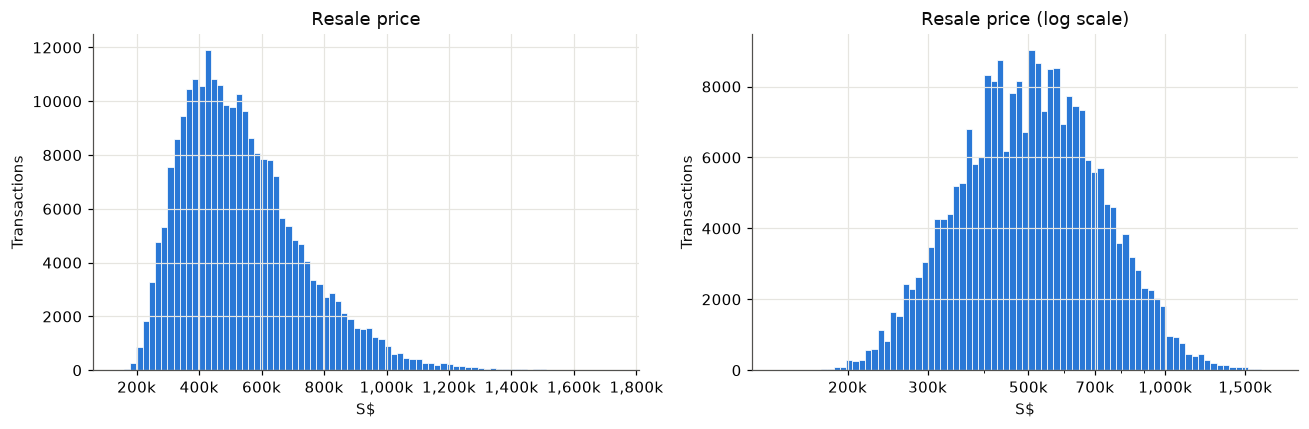

In [15]:
# Same prices, two scales: linear (left) and log (right)
fig, (ax_lin, ax_log) = plt.subplots(1, 2, figsize=(12, 4))

ax_lin.hist(
    raw["resale_price"], bins=80, color=SERIES[0], edgecolor="white", linewidth=0.5
)
ax_lin.xaxis.set_major_formatter(thousands)
ax_lin.set(title="Resale price", xlabel="S$", ylabel="Transactions")

log_bins = np.logspace(
    np.log10(raw["resale_price"].min()), np.log10(raw["resale_price"].max()), 80
)
ax_log.hist(
    raw["resale_price"],
    bins=log_bins,
    color=SERIES[0],
    edgecolor="white",
    linewidth=0.5,
)
ax_log.set_xscale("log")
ax_log.xaxis.set_major_locator(
    mticker.FixedLocator([200e3, 300e3, 500e3, 700e3, 1e6, 1.5e6])
)
ax_log.xaxis.set_major_formatter(thousands)
ax_log.xaxis.set_minor_formatter(mticker.NullFormatter())
ax_log.set(title="Resale price (log scale)", xlabel="S$", ylabel="Transactions")

plt.tight_layout()

### Trend over time

Median price per registration month, overall and for the four main flat types. The last month is incomplete (registration lag), so its median rests on fewer sales.

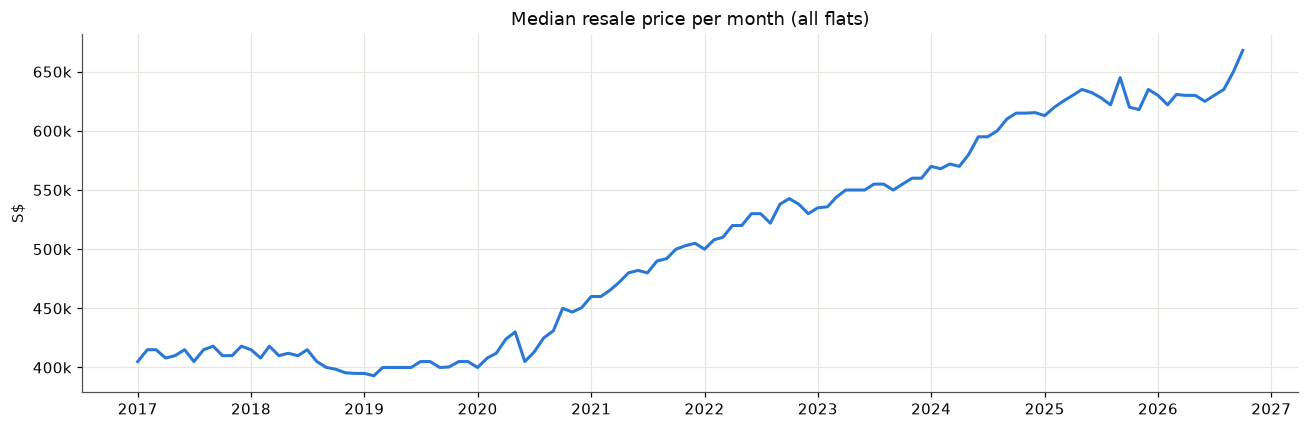

In [16]:
# Median price per month, overall
monthly = raw.groupby("month")["resale_price"].agg(["median", "size"])
monthly.index = pd.PeriodIndex(monthly.index, freq="M").to_timestamp()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index, monthly["median"], color=SERIES[0])
ax.yaxis.set_major_formatter(thousands)
ax.set(title="Median resale price per month (all flats)", ylabel="S$")
plt.tight_layout()

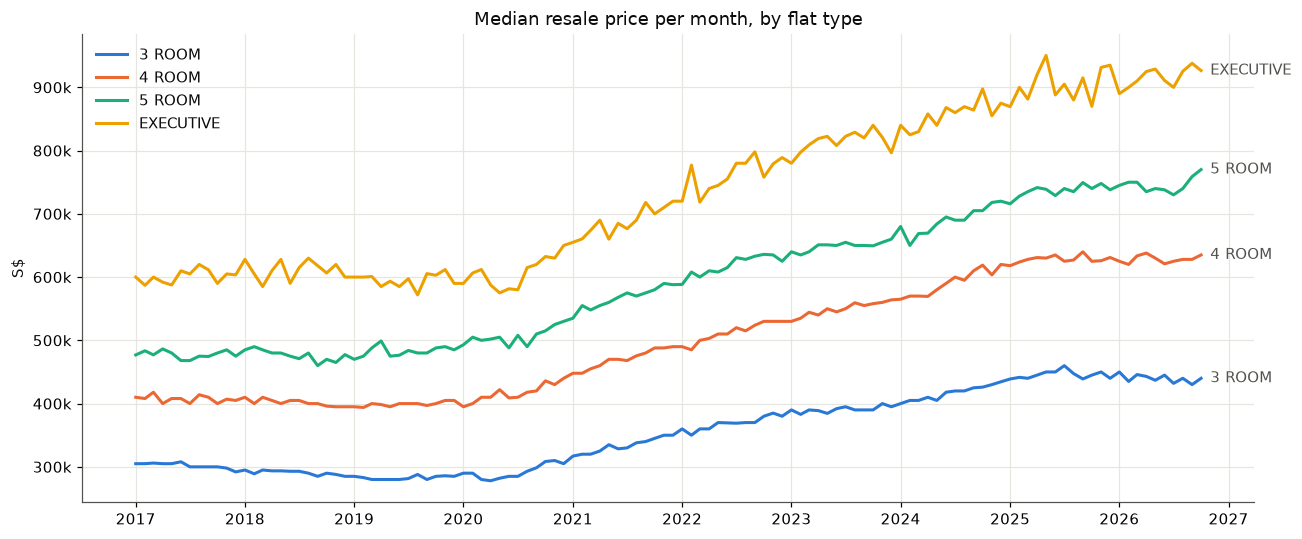

In [17]:
# Median price per month for the four most common flat types (the other three are rare)
main_types = raw["flat_type"].value_counts().index[:4].sort_values()
by_type = (
    raw[raw["flat_type"].isin(main_types)]
    .groupby(["month", "flat_type"])["resale_price"]
    .median()
    .unstack()
)
by_type.index = pd.PeriodIndex(by_type.index, freq="M").to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
for color, flat_type in zip(SERIES, main_types, strict=True):
    ax.plot(by_type.index, by_type[flat_type], color=color, label=flat_type)
    # Direct label at the end of each line, so identity doesn't rely on colour alone
    ax.annotate(
        flat_type,
        (by_type.index[-1], by_type[flat_type].iloc[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        color="#52514e",
    )
ax.yaxis.set_major_formatter(thousands)
ax.legend(loc="upper left", frameon=False)
ax.set(title="Median resale price per month, by flat type", ylabel="S$")
plt.tight_layout()

In [18]:
# How much did the median rise? First full year (2017) vs the last 12 complete months
year = raw["month"].str[:4]
first_year = raw.loc[year == "2017", "resale_price"].median()
complete_months = sorted(raw["month"].unique())[
    :-1
]  # drop the incomplete current month
last_12 = raw.loc[raw["month"].isin(complete_months[-12:]), "resale_price"].median()
print(f"2017 median:                 S${first_year:,.0f}")
print(
    f"Last 12 full months median:  S${last_12:,.0f}  ({complete_months[-12]} to {complete_months[-1]})"
)
print(f"Change:                      {last_12 / first_year - 1:+.0%}")

2017 median:                 S$410,000
Last 12 full months median:  S$630,000  (2025-10 to 2026-09)
Change:                      +54%


### Findings (section 2)

- **Median S\$505k** over 2017–2026, about S\$630k recently. The prediction (S\$1.0–1.1M) matched the **99th percentile**, not the median: a sampling bias from a personal flat search focused on expensive flats.
- **Right-skewed** (skewness ≈ 1), as predicted, and **nearly symmetric on a log scale**: prices differ multiplicatively, so model the **log of the price**.
- **Three regimes:** flat 2017–2019, a sharp rise 2020–2025 (about +50%), a plateau since mid-2025. The prediction (+8%) reflected only the recent plateau.
- The rise holds **within every flat type**, so it's a real price change, not a composition effect (more large flats being sold).
- **Modeling consequences:** the model must know *when* a sale happened, and the regime changes make the training window length (expanding vs sliding) worth testing in the backtest.

## 3. What drives price besides time

**Predictions (before running):** floor area is the strongest driver, strongly collinear with flat type (room sizes are fairly standard in Singapore); location (town) is a major driver; remaining lease is a major driver, collinear with lease commencement date; storey matters, but less.

To compare flats of different sizes fairly, most charts below use the **price per square metre**.

*The quick conversions in this section (lease, storey) are exploration only: the real cleaning code goes into the package in the next sub-step.*

In [19]:
# Exploration-only helper columns (proper cleaning comes in the package later)
eda = raw.copy()
eda["price_per_sqm"] = eda["resale_price"] / eda["floor_area_sqm"]

# "61 years 04 months" -> 61.33 years
lease_parts = (
    eda["remaining_lease"].str.extract(r"(\d+) years?(?: (\d+) months?)?").astype(float)
)
eda["remaining_lease_years"] = lease_parts[0] + lease_parts[1].fillna(0) / 12

# "10 TO 12" -> 11 (middle storey)
storey_bounds = eda["storey_range"].str.extract(r"(\d+) TO (\d+)").astype(int)
eda["storey_mid"] = storey_bounds.mean(axis=1)

eda[
    [
        "remaining_lease",
        "remaining_lease_years",
        "storey_range",
        "storey_mid",
        "price_per_sqm",
    ]
].head()

,remaining_lease,remaining_lease_years,storey_range,storey_mid,price_per_sqm
0,61 years 04 months,61.333333,10 TO 12,11.0,5272.727273
1,60 years 07 months,60.583333,01 TO 03,2.0,3731.343284
2,62 years 05 months,62.416667,01 TO 03,2.0,3910.447761
3,62 years 01 month,62.083333,04 TO 06,5.0,3897.058824
4,62 years 05 months,62.416667,01 TO 03,2.0,3955.223881


### Size: floor area and flat type

Correlation, floor area vs price: 0.56


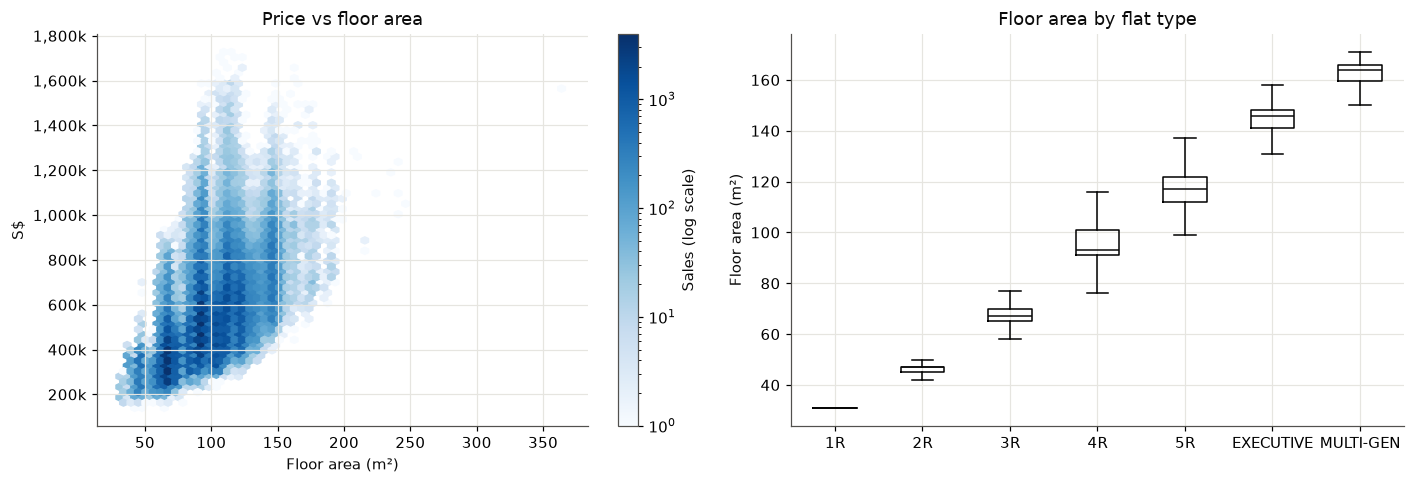

In [20]:
# Price vs floor area: 240k points, so a density plot (darker = more sales) instead of a scatter
fig, (ax_area, ax_type) = plt.subplots(1, 2, figsize=(13, 4.5))

hb = ax_area.hexbin(
    eda["floor_area_sqm"],
    eda["resale_price"],
    gridsize=60,
    cmap="Blues",
    mincnt=1,
    bins="log",
)
ax_area.yaxis.set_major_formatter(thousands)
ax_area.set(title="Price vs floor area", xlabel="Floor area (m²)", ylabel="S$")
fig.colorbar(hb, ax=ax_area, label="Sales (log scale)")

# Floor area per flat type, ordered from smallest to largest
type_order = [
    "1 ROOM",
    "2 ROOM",
    "3 ROOM",
    "4 ROOM",
    "5 ROOM",
    "EXECUTIVE",
    "MULTI-GENERATION",
]
ax_type.boxplot(
    [eda.loc[eda["flat_type"] == t, "floor_area_sqm"] for t in type_order],
    tick_labels=[
        t.replace(" ROOM", "R").replace("MULTI-GENERATION", "MULTI-GEN")
        for t in type_order
    ],
    showfliers=False,
    medianprops={"color": "#0b0b0b"},
)
ax_type.set(title="Floor area by flat type", ylabel="Floor area (m²)")
plt.tight_layout()

print(
    f"Correlation, floor area vs price: {eda['floor_area_sqm'].corr(eda['resale_price']):.2f}"
)

### Location: town

Most / least expensive town: 1.7x per m²


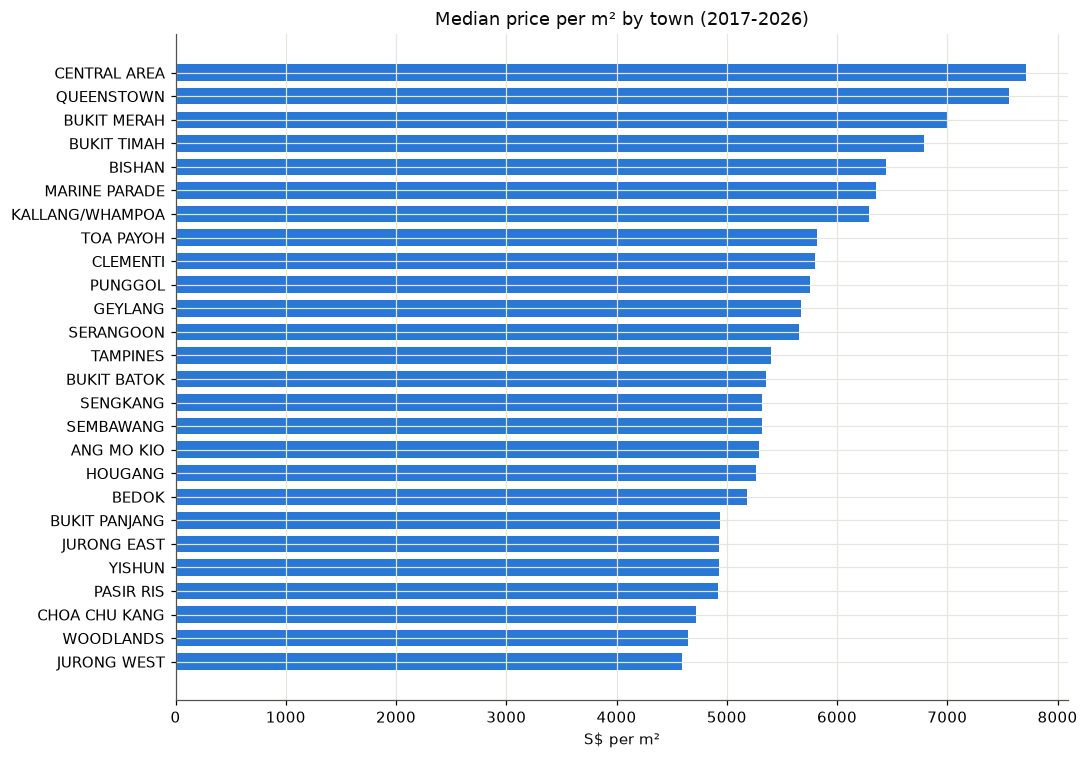

In [21]:
# Median price per m² by town, sorted: isolates location from flat size
town_ppsqm = eda.groupby("town")["price_per_sqm"].median().sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(town_ppsqm.index, town_ppsqm.values, color=SERIES[0], height=0.7)
ax.set(title="Median price per m² by town (2017-2026)", xlabel="S$ per m²")
plt.tight_layout()

print(f"Most / least expensive town: {town_ppsqm.max() / town_ppsqm.min():.1f}x per m²")

### Age: remaining lease

Correlation, remaining lease vs 99 - age: 1.000
Gap between the two: median 0.50 years, 99th percentile 1.00 years


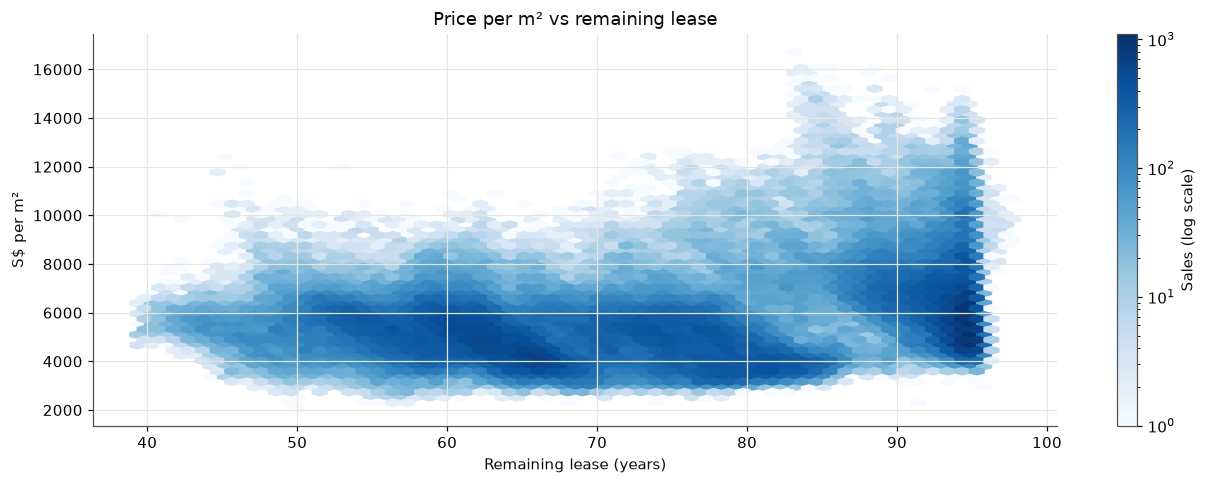

In [22]:
# Remaining lease vs price per m²; then how redundant it is with lease commencement date
fig, ax = plt.subplots(figsize=(12, 4.5))
hb = ax.hexbin(
    eda["remaining_lease_years"],
    eda["price_per_sqm"],
    gridsize=60,
    cmap="Blues",
    mincnt=1,
    bins="log",
)
ax.set(
    title="Price per m² vs remaining lease",
    xlabel="Remaining lease (years)",
    ylabel="S$ per m²",
)
fig.colorbar(hb, ax=ax, label="Sales (log scale)")
plt.tight_layout()

# HDB leases are 99 years: remaining lease should be 99 - (sale year - lease start)
sale_year = (
    eda["month"].str[:4].astype(int) + (eda["month"].str[5:7].astype(int) - 1) / 12
)
implied_remaining = 99 - (sale_year - eda["lease_commence_date"])
gap = (eda["remaining_lease_years"] - implied_remaining).abs()
print(
    f"Correlation, remaining lease vs 99 - age: {eda['remaining_lease_years'].corr(implied_remaining):.3f}"
)
print(
    f"Gap between the two: median {gap.median():.2f} years, 99th percentile {gap.quantile(0.99):.2f} years"
)

### Height: storey

,median,size
storey_mid,,
2.0,4888.888889,42520
5.0,5109.375000,55625
8.0,5268.817204,50832
11.0,5384.615385,45285
14.0,5741.071429,23439
17.0,6176.470588,10981
20.0,6964.285714,4757
23.0,7282.608696,3321
26.0,8241.816812,2072


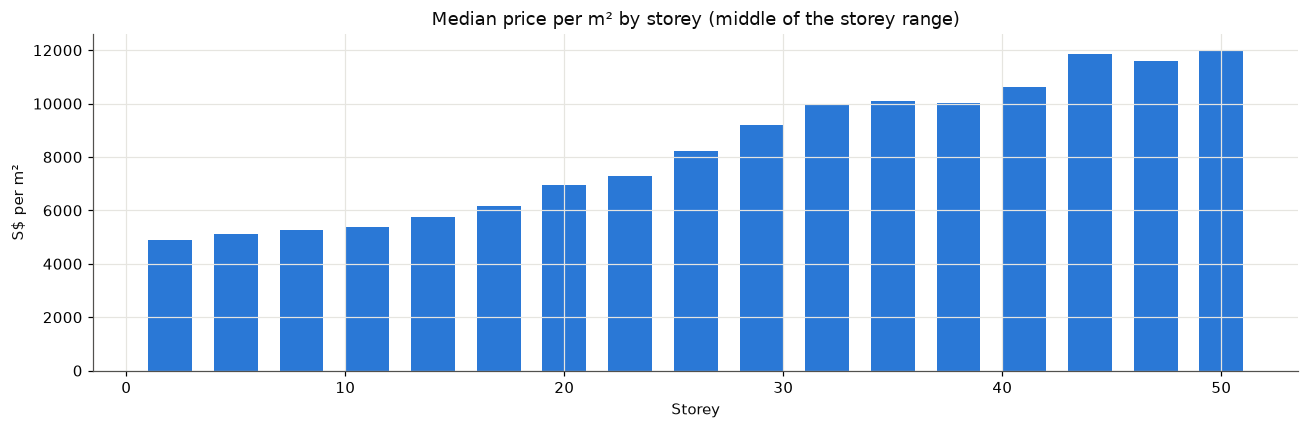

In [23]:
# Median price per m² per storey range, from lowest to highest floor
storey = eda.groupby("storey_mid")["price_per_sqm"].agg(["median", "size"])

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(storey.index, storey["median"], width=2, color=SERIES[0])
ax.set(
    title="Median price per m² by storey (middle of the storey range)",
    xlabel="Storey",
    ylabel="S$ per m²",
)
plt.tight_layout()

storey

### All numeric drivers together

Spearman correlation (based on ranks, so it captures any monotonic relationship, not just straight lines), including time as a number of months since Jan 2017.

In [24]:
# Rank correlations between the numeric drivers and the log price
eda["months_since_2017"] = (sale_year - 2017) * 12
eda["log_price"] = np.log(eda["resale_price"])
numeric = [
    "log_price",
    "floor_area_sqm",
    "remaining_lease_years",
    "lease_commence_date",
    "storey_mid",
    "months_since_2017",
]
eda[numeric].corr(method="spearman").round(2)

,log_price,floor_area_sqm,remaining_lease_years,lease_commence_date,storey_mid,months_since_2017
log_price,1.00,0.60,0.32,0.42,0.25,0.44
floor_area_sqm,0.60,1.00,0.15,0.16,0.01,-0.03
remaining_lease_years,0.32,0.15,1.00,0.97,0.24,-0.08
lease_commence_date,0.42,0.16,0.97,1.00,0.24,0.13
storey_mid,0.25,0.01,0.24,0.24,1.00,0.01
months_since_2017,0.44,-0.03,-0.08,0.13,0.01,1.00
